In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("main.csv")
df.head()

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [3]:
df.shape

(4005, 19)

In [4]:
df.columns.to_list()

['talk_id',
 'title',
 'speaker_1',
 'all_speakers',
 'occupations',
 'about_speakers',
 'views',
 'recorded_date',
 'published_date',
 'event',
 'native_lang',
 'available_lang',
 'comments',
 'duration',
 'topics',
 'related_talks',
 'url',
 'description',
 'transcript']

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   talk_id         4005 non-null   int64  
 1   title           4005 non-null   object 
 2   speaker_1       4005 non-null   object 
 3   all_speakers    4001 non-null   object 
 4   occupations     3483 non-null   object 
 5   about_speakers  3502 non-null   object 
 6   views           4005 non-null   int64  
 7   recorded_date   4004 non-null   object 
 8   published_date  4005 non-null   object 
 9   event           4005 non-null   object 
 10  native_lang     4005 non-null   object 
 11  available_lang  4005 non-null   object 
 12  comments        3350 non-null   float64
 13  duration        4005 non-null   int64  
 14  topics          4005 non-null   object 
 15  related_talks   4005 non-null   object 
 16  url             4005 non-null   object 
 17  description     4005 non-null   o

In [6]:
df.isnull().sum()

talk_id             0
title               0
speaker_1           0
all_speakers        4
occupations       522
about_speakers    503
views               0
recorded_date       1
published_date      0
event               0
native_lang         0
available_lang      0
comments          655
duration            0
topics              0
related_talks       0
url                 0
description         0
transcript          0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.corr(numeric_only =True)

,talk_id,views,comments,duration
talk_id,1.000000,-0.113291,-0.232926,-0.261955
views,-0.113291,1.000000,0.500748,0.073642
comments,-0.232926,0.500748,1.000000,0.175234
duration,-0.261955,0.073642,0.175234,1.000000


In [9]:
# df.loc[df['talk_id']==92,'speaker_1']

In [10]:
cols=df.select_dtypes(include='object').columns
df[cols]=df[cols].apply(lambda col:col.str.strip())

In [11]:
df['duration'].value_counts()

duration
274     13
285     12
276     12
303     12
289     11
        ..
1220     1
611      1
441      1
123      1
147      1
Name: count, Length: 1188, dtype: int64

In [12]:
df.loc[df['duration'] < 100, ['title', 'duration','url']]

,title,duration,url
3516,"""Three Months After""",78,https://www.ted.com/talks/cristin_o_keefe_apto...
3554,"""New Colossus""",78,https://www.ted.com/talks/emma_lazarus_new_col...
3623,"""Ode to the Only Black Kid in the Class""",60,https://www.ted.com/talks/clint_smith_ode_to_t...


In [13]:
for col in df.select_dtypes(include='object').columns:
    print(col, (df[col].dropna() != df[col].dropna().str.strip()).sum())

title 0
speaker_1 0
all_speakers 0
occupations 0
about_speakers 0
recorded_date 0
published_date 0
event 0
native_lang 0
available_lang 0
topics 0
related_talks 0
url 0
description 0
transcript 0


In [14]:
print("Duplicate titles:", df['title'].duplicated().sum())
print("Zero/negative durations:", (df['duration'] <= 0).sum())
print("Empty titles:", df['title'].astype(str).str.strip().eq('').sum())

Duplicate titles: 0
Zero/negative durations: 0
Empty titles: 0


In [15]:
df = df.dropna(subset=['recorded_date'])
df['occupations'] = df['occupations'].fillna("Unknown")
df['about_speakers'] = df['about_speakers'].fillna("No information")

In [16]:
df[['speaker_1', 'all_speakers']].head()

,speaker_1,all_speakers
0,Al Gore,{0: 'Al Gore'}
1,Hans Rosling,{0: 'Hans Rosling'}
2,David Pogue,{0: 'David Pogue'}
3,Majora Carter,{0: 'Majora Carter'}
4,Sir Ken Robinson,{0: 'Sir Ken Robinson'}


In [17]:
df.loc[df['all_speakers'].isna() , 'speaker_1']

2927    Antón García-Abril
3266            Keith Lowe
3290       Maisie Williams
3665        Zohreh Davoudi
Name: speaker_1, dtype: object

In [18]:
df['all_speakers'] = df.apply(
    lambda row: {0: row['speaker_1']} if pd.isna(row['all_speakers']) else row['all_speakers'],
    axis=1
)

In [19]:
df['comments'] = df['comments'].fillna(df['comments'].median())

In [20]:
df.isnull().sum()

talk_id           0
title             0
speaker_1         0
all_speakers      0
occupations       0
about_speakers    0
views             0
recorded_date     0
published_date    0
event             0
native_lang       0
available_lang    0
comments          0
duration          0
topics            0
related_talks     0
url               0
description       0
transcript        0
dtype: int64

<h2>Lowercase </h2>

In [21]:
df.select_dtypes(include='object').columns

Index(['title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers',
       'recorded_date', 'published_date', 'event', 'native_lang',
       'available_lang', 'topics', 'related_talks', 'url', 'description',
       'transcript'],
      dtype='object')

In [22]:
print(type(df['all_speakers'].dropna().iloc[0]))
print(type(df['topics'].dropna().iloc[0]))
print(type(df['related_talks'].dropna().iloc[0]))

<class 'str'>
<class 'str'>
<class 'str'>


In [23]:
str_cols =[ 'speaker_1', 'all_speakers', 'occupations', 'about_speakers',
        'event', 'native_lang','available_lang', 'topics', 'related_talks', 'description',
       'transcript'] 

for col in str_cols:
    df[col] = df[col].str.lower()

df.head(1)

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,al gore,{0: 'al gore'},{0: ['climate advocate']},{0: 'nobel laureate al gore focused the world’...,3523392,2006-02-25,2006-06-27,ted2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'new thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,with the same humor and humanity he exuded in ...,"thank you so much, chris. and it's truly a gre..."


<h2>Remove URLs and Links</h2>

In [24]:
import re

str_cols = [
    'transcript', 'description', 'about_speakers',
    'speaker_1', 'all_speakers', 'topics'
]

for col in str_cols:
    df[col] = df[col].str.replace(
        r'https?://\S+|www\.\S+',
        '',
        regex=True
    )

<h2>Removal of special characters and Emojis</h2>

In [25]:
for col in str_cols:
    df[col] = df[col].str.replace(r'[^a-zA-Z0-9\s]', '', regex=True)

In [26]:
df['views'].value_counts()

views
0           6
1446787     2
1968363     2
806149      2
1454261     2
           ..
11430399    1
1329537     1
4032164     1
2554136     1
570089      1
Name: count, Length: 3995, dtype: int64

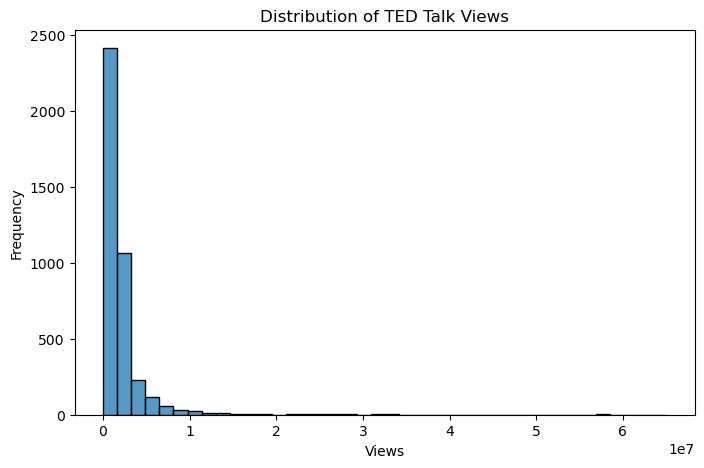

In [27]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='views', bins=40)
plt.title('Distribution of TED Talk Views')
plt.xlabel('Views')
plt.ylabel('Frequency')
plt.show()

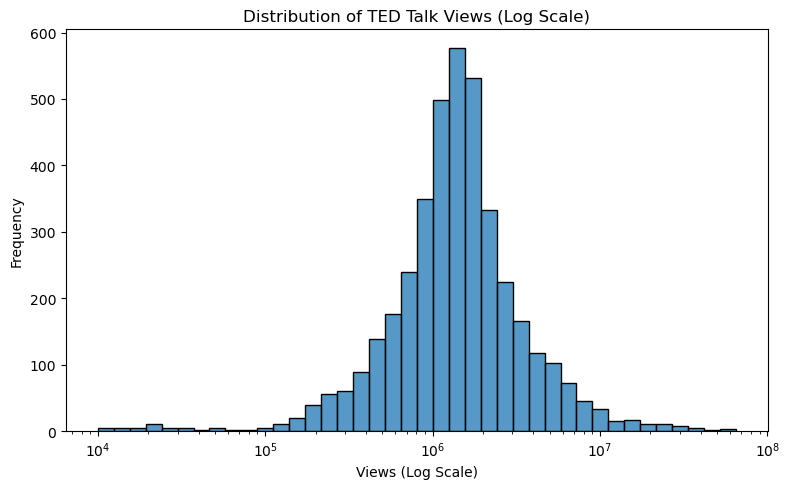

In [28]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='views',
    bins=40,
    log_scale=True
)

plt.title('Distribution of TED Talk Views (Log Scale)')
plt.xlabel('Views (Log Scale)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

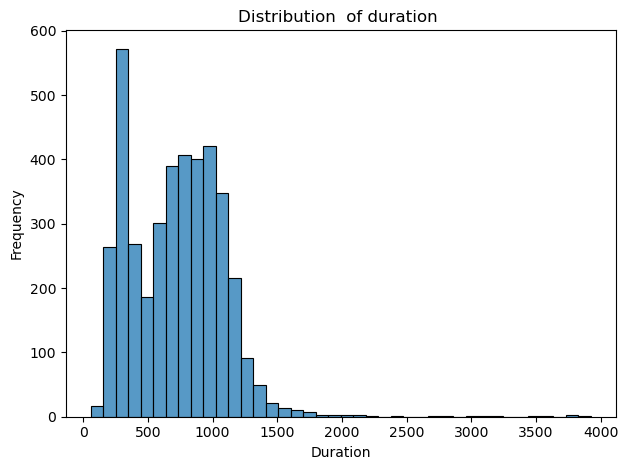

In [29]:
sns.histplot(data=df,x='duration', bins=40)
plt.title('Distribution  of duration ')
plt.xlabel('Duration')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

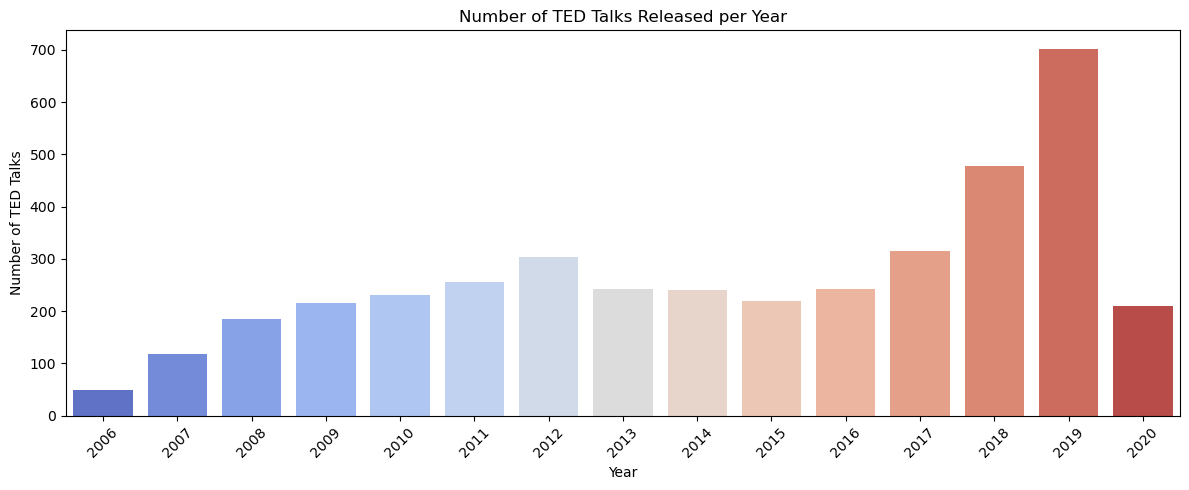

In [30]:
df['published_date'] = pd.to_datetime(df['published_date'], errors='coerce')
df['year'] = df['published_date'].dt.year

year_counts = df['year'].value_counts().sort_index()

plt.figure(figsize=(12, 5))
sns.barplot(x=year_counts.index, y=year_counts.values,palette='coolwarm')

plt.title('Number of TED Talks Released per Year')
plt.xlabel('Year')
plt.ylabel('Number of TED Talks')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

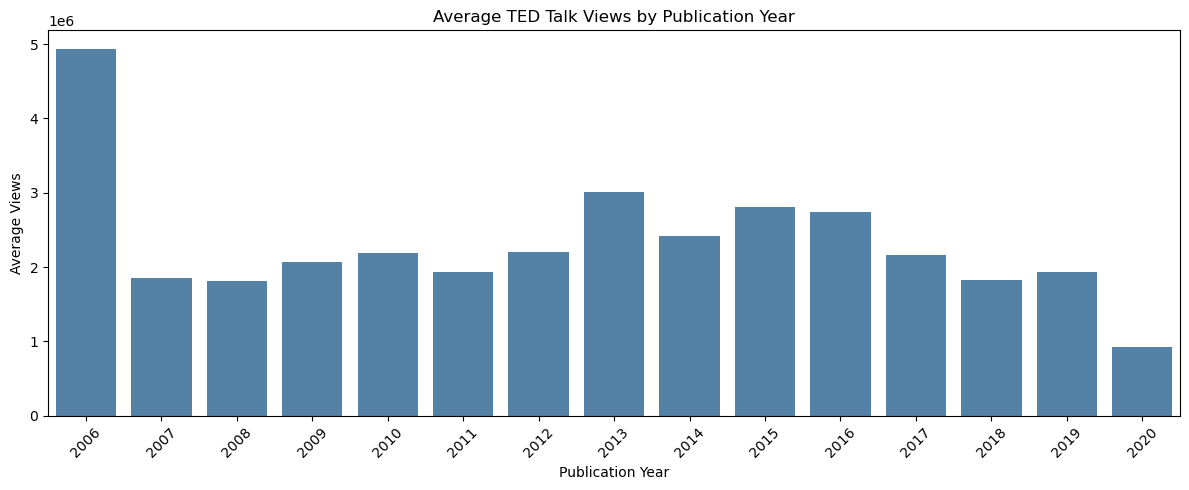

In [31]:
year_views = df.groupby('year')['views'].mean()

plt.figure(figsize=(12, 5))
sns.barplot(x=year_views.index, y=year_views.values, color='steelblue')

plt.title('Average TED Talk Views by Publication Year')
plt.xlabel('Publication Year')
plt.ylabel('Average Views')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
df.columns

Index(['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations',
       'about_speakers', 'views', 'recorded_date', 'published_date', 'event',
       'native_lang', 'available_lang', 'comments', 'duration', 'topics',
       'related_talks', 'url', 'description', 'transcript', 'year'],
      dtype='object')

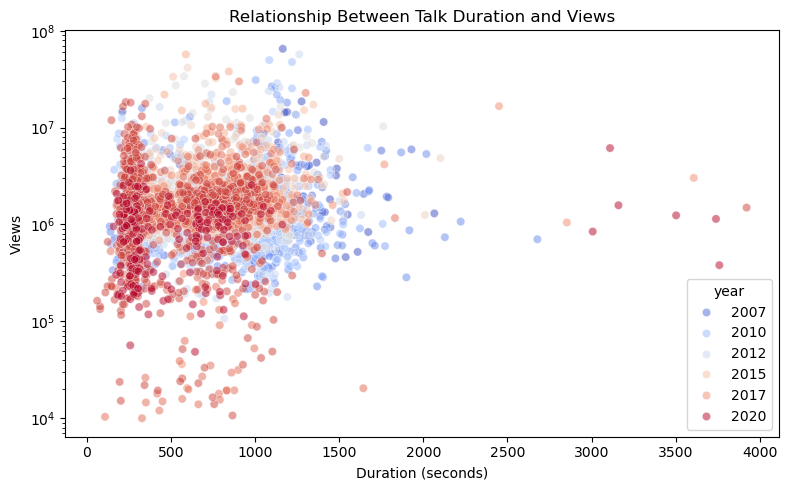

In [33]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='duration', y='views',hue='year',alpha=0.5,palette='coolwarm')

plt.title('Relationship Between Talk Duration and Views')
plt.xlabel('Duration (seconds)')
plt.ylabel('Views')
plt.yscale('log')
plt.tight_layout()
plt.show()

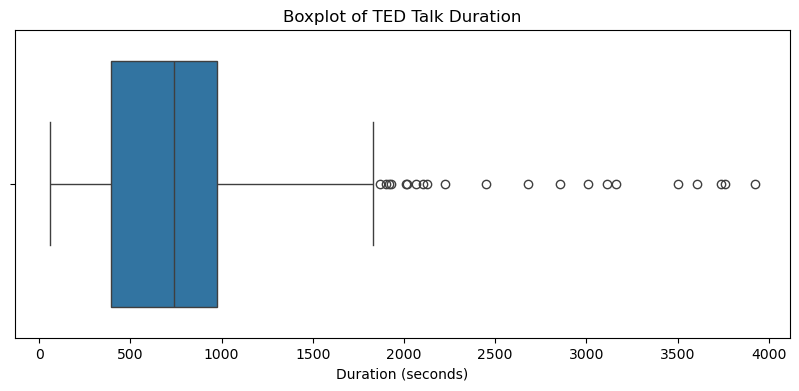

In [34]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['duration'])
plt.title('Boxplot of TED Talk Duration')
plt.xlabel('Duration (seconds)')
plt.show()

In [35]:
df[['speaker_1', 'all_speakers']].head(10)

,speaker_1,all_speakers
0,al gore,0 al gore
1,hans rosling,0 hans rosling
2,david pogue,0 david pogue
3,majora carter,0 majora carter
4,sir ken robinson,0 sir ken robinson
5,joshua princeramus,0 joshua princeramus
6,julia sweeney,0 julia sweeney
7,dan dennett,0 dan dennett
8,rick warren,0 rick warren
9,jehane noujaim,0 jehane noujaim


In [36]:
df['all_speakers'] = df['all_speakers'].str.replace(
    r'^\d+\s*', '', regex=True
).str.strip()

In [37]:
df[['speaker_1', 'all_speakers']].head(10)

,speaker_1,all_speakers
0,al gore,al gore
1,hans rosling,hans rosling
2,david pogue,david pogue
3,majora carter,majora carter
4,sir ken robinson,sir ken robinson
5,joshua princeramus,joshua princeramus
6,julia sweeney,julia sweeney
7,dan dennett,dan dennett
8,rick warren,rick warren
9,jehane noujaim,jehane noujaim


In [38]:
print(df.columns.tolist())

['talk_id', 'title', 'speaker_1', 'all_speakers', 'occupations', 'about_speakers', 'views', 'recorded_date', 'published_date', 'event', 'native_lang', 'available_lang', 'comments', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'year']


In [39]:
df.isnull().sum().sort_values(ascending=False)

all_speakers      4
talk_id           0
title             0
speaker_1         0
occupations       0
about_speakers    0
views             0
recorded_date     0
published_date    0
event             0
native_lang       0
available_lang    0
comments          0
duration          0
topics            0
related_talks     0
url               0
description       0
transcript        0
year              0
dtype: int64

In [40]:
df['all_speakers'] = df['all_speakers'].fillna(df['speaker_1'])

In [41]:
df.isnull().sum().sort_values(ascending=False)

talk_id           0
title             0
speaker_1         0
all_speakers      0
occupations       0
about_speakers    0
views             0
recorded_date     0
published_date    0
event             0
native_lang       0
available_lang    0
comments          0
duration          0
topics            0
related_talks     0
url               0
description       0
transcript        0
year              0
dtype: int64

In [42]:
import os
print(os.getcwd())

C:\Users\Mukesh\springboard


In [43]:
df['native_lang'].nunique()

12

In [44]:
df['native_lang'].value_counts()

native_lang
en       3956
es         27
fr          9
ja          3
hi          2
de          1
pt          1
ko          1
pt-br       1
ar          1
zh-cn       1
it          1
Name: count, dtype: int64

In [45]:
df["available_lang"].nunique()

3901

In [46]:
df.columns.to_list()

['talk_id',
 'title',
 'speaker_1',
 'all_speakers',
 'occupations',
 'about_speakers',
 'views',
 'recorded_date',
 'published_date',
 'event',
 'native_lang',
 'available_lang',
 'comments',
 'duration',
 'topics',
 'related_talks',
 'url',
 'description',
 'transcript',
 'year']

In [47]:
top_10 = df.nlargest(10, 'views')[['title', 'speaker_1', 'views']]

In [48]:
top_10

,title,speaker_1,views
4,Do schools kill creativity?,sir ken robinson,65051954
1296,Your body language may shape who you are,amy cuddy,57074270
2062,This is what happens when you reply to spam email,james veitch,56932551
646,How great leaders inspire action,simon sinek,49730580
796,The power of vulnerability,bren brown,47544833
1724,How to speak so that people want to listen,julian treasure,41504331
2108,Inside the mind of a master procrastinator,tim urban,37976820
1366,"Looks aren't everything. Believe me, I'm a model.",cameron russell,33874546
2724,My philosophy for a happy life,sam berns,33691484
1898,The next outbreak? We're not ready,bill gates,33521780


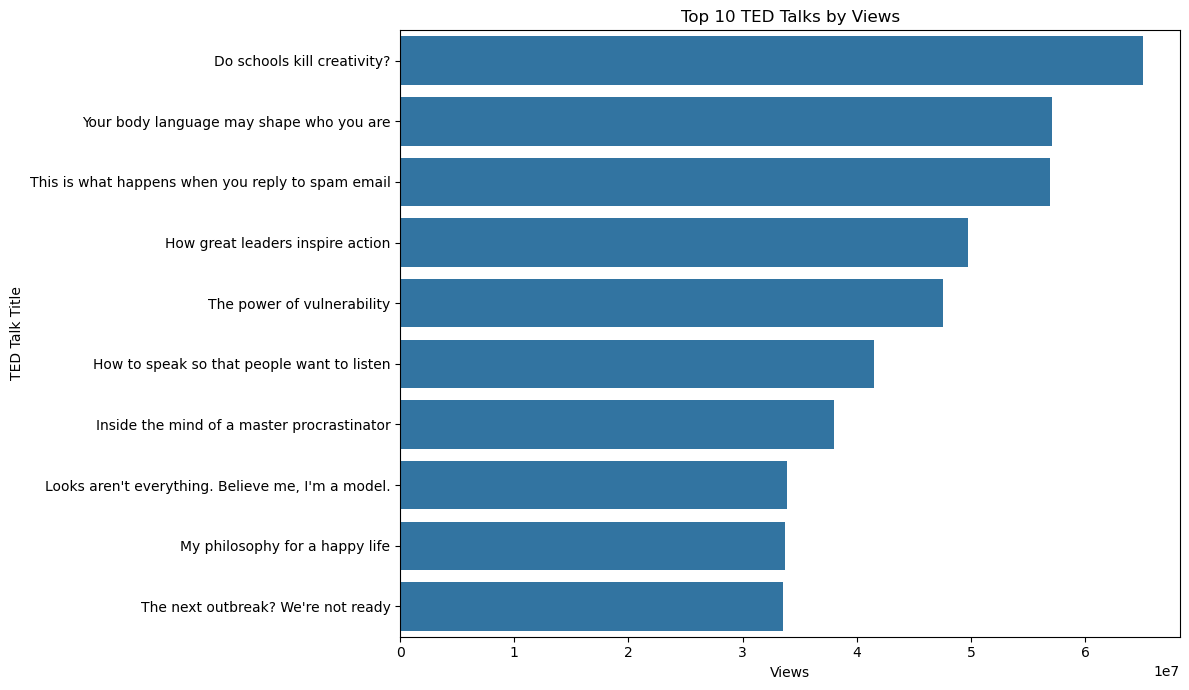

In [49]:
top_ted_talks= df.nlargest(10,'views')
plt.figure(figsize=(12,7))
sns.barplot(data=top_ted_talks,x='views',y='title')

plt.title('Top 10 TED Talks by Views')
plt.xlabel('Views')
plt.ylabel('TED Talk Title')
plt.tight_layout()
plt.show()

In [50]:
df['topics'].value_counts()

topics
teded math                                                                                    8
animation teded math                                                                          5
teded math animation                                                                          3
teded animation education math                                                                3
cities culture design transportation                                                          2
                                                                                             ..
business collaboration culture global issues library opensource technology                    1
collaboration comedy community culture dance demo entertainment software performance humor    1
business communication community culture design entertainment software storytelling           1
cognitive science culture evolution gender love psychology relationships science              1
architecture collaboration cultur

In [51]:
df['views'].describe()

count    4.004000e+03
mean     2.148223e+06
std      3.451629e+06
min      0.000000e+00
25%      8.817605e+05
50%      1.375594e+06
75%      2.133174e+06
max      6.505195e+07
Name: views, dtype: float64

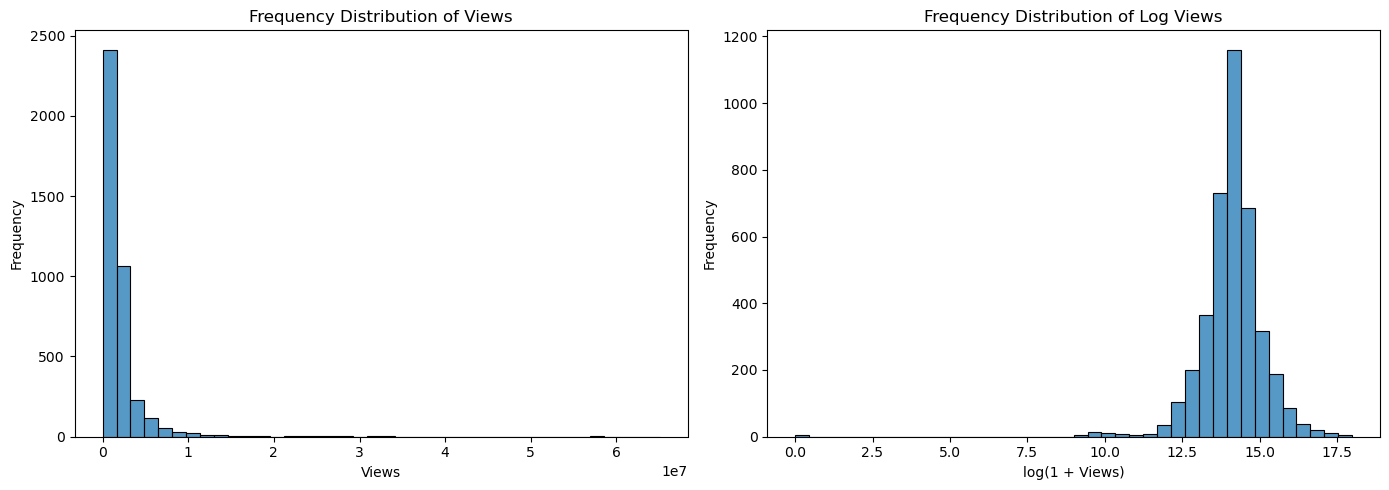

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Normal views frequency
sns.histplot(data=df, x='views', bins=40, ax=axes[0])
axes[0].set_title('Frequency Distribution of Views')
axes[0].set_xlabel('Views')
axes[0].set_ylabel('Frequency')

# Log-transformed views frequency
sns.histplot(
    x=np.log1p(df['views'].dropna()),
    bins=40,
    ax=axes[1]
)
axes[1].set_title('Frequency Distribution of Log Views')
axes[1].set_xlabel('log(1 + Views)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

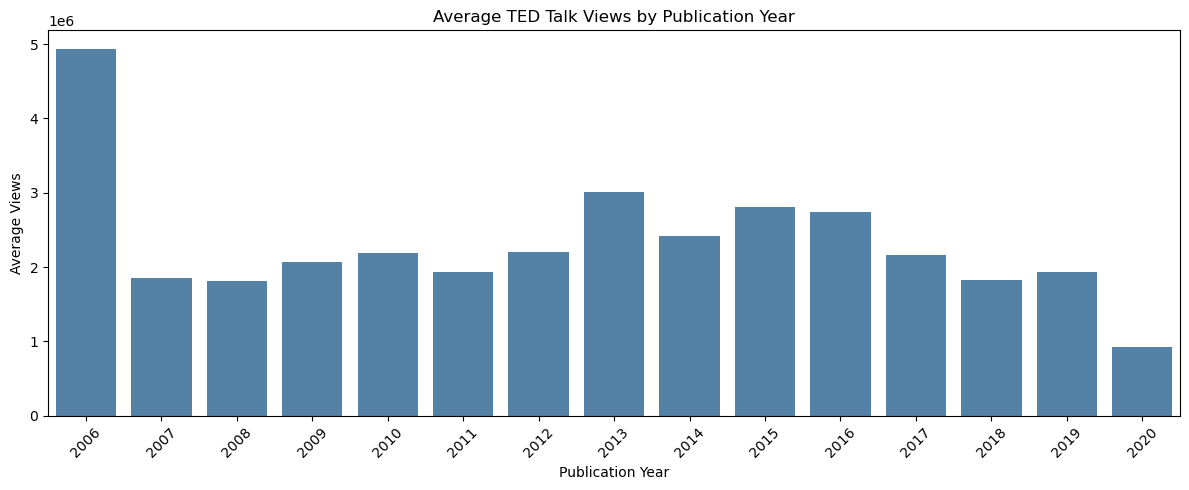

In [53]:
year_views = df.groupby('year')['views'].mean().dropna()

plt.figure(figsize=(12, 5))
sns.barplot(x=year_views.index, y=year_views.values, color='steelblue')

plt.title('Average TED Talk Views by Publication Year')
plt.xlabel('Publication Year')
plt.ylabel('Average Views')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [54]:
df['speaker_1'].nunique()

3273

In [55]:
top_speakers = df['speaker_1'].value_counts()
top_speakers = top_speakers.head(10).reset_index()
top_speakers.columns = ['speakers_1', 'count']

In [56]:
top_speakers.head(10)

,speakers_1,count
0,alex gendler,34
1,iseult gillespie,19
2,emma bryce,12
3,daniel finkel,11
4,hans rosling,10
5,alex rosenthal,10
6,juan enriquez,9
7,greg gage,9
8,chris anderson,8
9,dan ariely,7


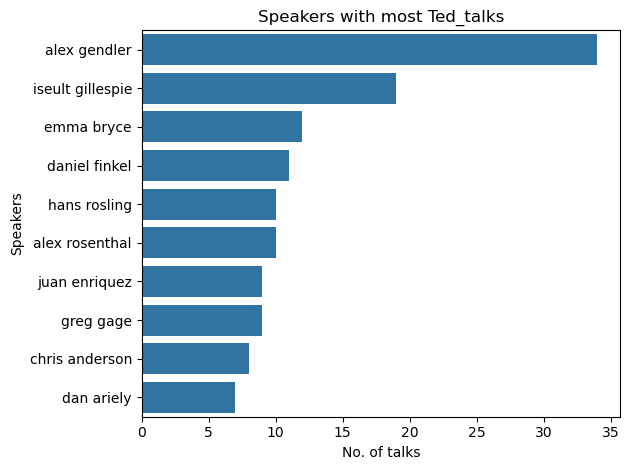

In [57]:
sns.barplot(data=top_speakers,x='count',y='speakers_1')
plt.title('Speakers with most Ted_talks')
plt.xlabel('No. of talks')
plt.ylabel('Speakers')
plt.tight_layout()
plt.show()

In [58]:
df.nlargest(10,'duration')[['title','duration','speaker_1']]

,title,duration,speaker_1
3768,How we can turn the tide on climate,3922,chris anderson
3965,The quest for the coronavirus vaccine,3760,seth berkley
3973,It's OK to feel overwhelmed. Here's what to do...,3740,elizabeth gilbert
2334,Nationalism vs. globalism: the new political d...,3608,yuval noah harari
3966,What the world can learn from China's response...,3503,gary liu
3982,What coronavirus means for the global economy,3160,ray dalio
3960,How we must respond to the coronavirus pandemic,3110,bill gates
3977,An ethical plan for ending the pandemic and re...,3007,danielle allen
2366,Political common ground in a polarized United ...,2853,gretchen carlson
198,My days as a young rebel,2678,frank gehry


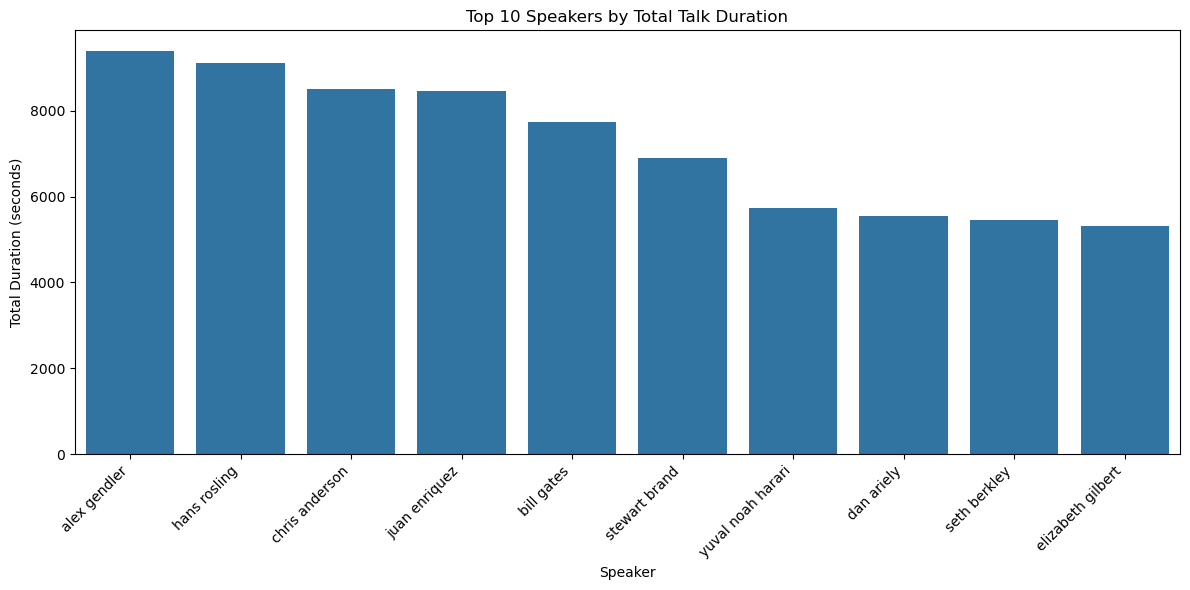

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

top_speakers_duration = (
    df.groupby('speaker_1')['duration']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_speakers_duration,
    x='speaker_1',
    y='duration'
)

plt.title('Top 10 Speakers by Total Talk Duration')
plt.xlabel('Speaker')
plt.ylabel('Total Duration (seconds)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

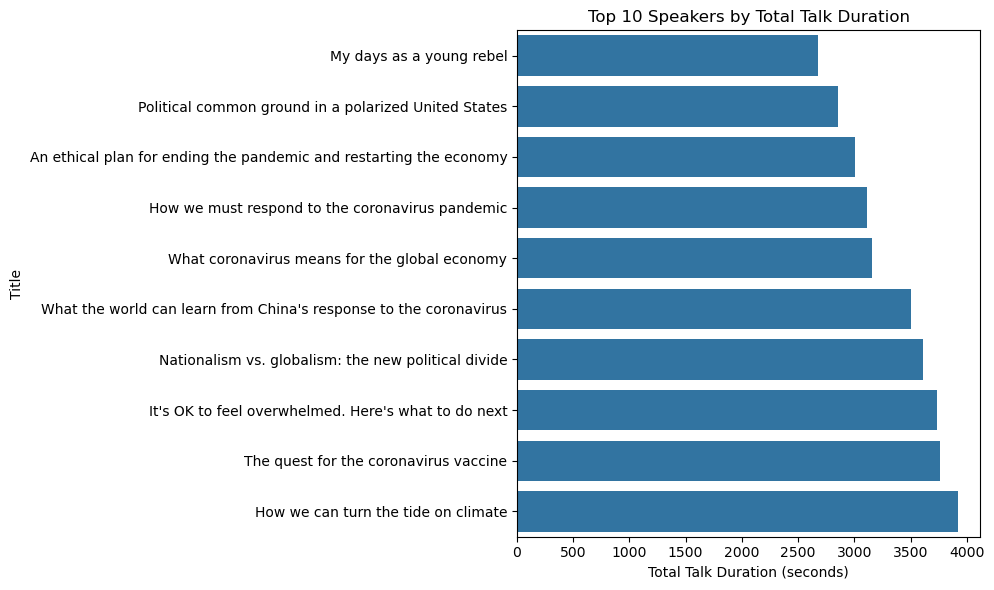

In [60]:
top_10 = (
    df.groupby('title')['duration']
    .sum()
    .nlargest(10)
    .sort_values()
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10,
    x='duration',
    y='title'
)

plt.title('Top 10 Speakers by Total Talk Duration')
plt.xlabel('Total Talk Duration (seconds)')
plt.ylabel('Title')
plt.tight_layout()
plt.show()

In [61]:
count = df['occupations'].value_counts()
count.head(10)

occupations
unknown                    522
{0: ['writer']}             53
{0: ['journalist']}         47
{0: ['entrepreneur']}       42
{0: ['artist']}             41
{0: ['architect']}          38
{0: ['designer']}           37
{0: ['neuroscientist']}     32
{0: ['psychologist']}       31
{0: ['educator']}           29
Name: count, dtype: int64

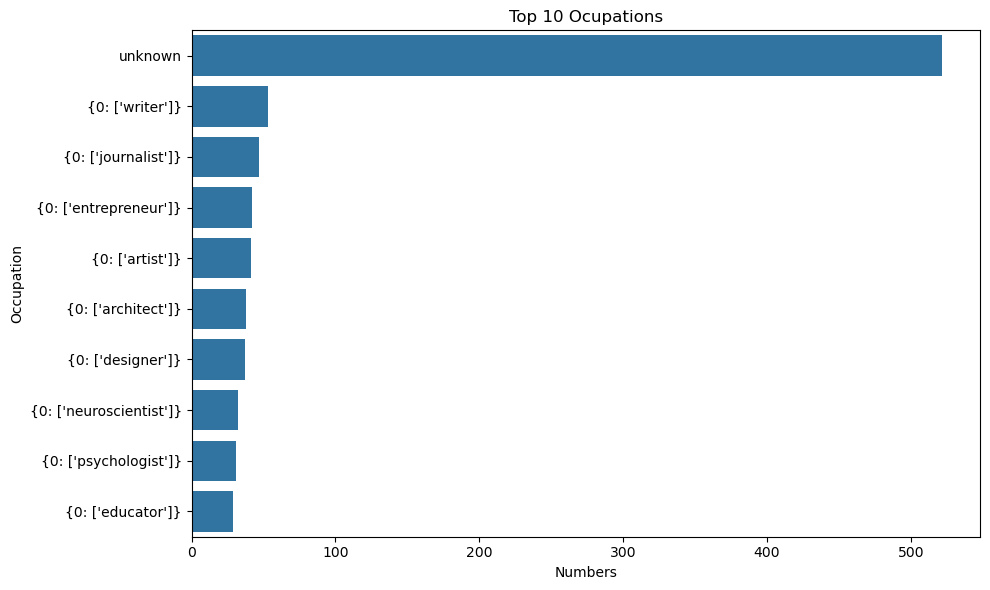

In [62]:
top_occupation = (
    df['occupations'].value_counts()
    .head(10)
    .reset_index()
)
top_occupation

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_occupation,
    x='count',
    y='occupations'
)

plt.title('Top 10 Ocupations')
plt.xlabel('Numbers')
plt.ylabel('Occupation')
plt.tight_layout()
plt.show()  


## This column become usless because unknown become the highest frequency so no use 

In [63]:
df[['all_speakers']]

,all_speakers
0,al gore
1,hans rosling
2,david pogue
3,majora carter
4,sir ken robinson
...,...
4000,nancy lublin
4001,stefan c dombrowski
4002,dick m carpenter ii
4003,daina ramey berry


In [64]:
df['all_speakers'] = (
    df['all_speakers']
    .str.replace(r'\d+', ',', regex=True)
    .str.replace(r',+', ',', regex=True)
    .str.strip(' ,')
)

In [65]:
unique_speakers = df.loc[df['speaker_1']!=df['all_speakers'],'all_speakers']
unique_speakers

91                             eddi reader , thomas dolby
92                             eddi reader , thomas dolby
95                        rachelle garniez , thomas dolby
98                       natalie macmaster , thomas dolby
99                               sergey brin , larry page
                              ...                        
3973    elizabeth gilbert , chris anderson , helen wal...
3977        danielle allen , chris anderson , corey hajim
3982             ray dalio , chris anderson , corey hajim
3990                        ebony roberts , shaka senghor
3999                     larry brilliant , chris anderson
Name: all_speakers, Length: 117, dtype: object

In [66]:
unique_speakers.nunique()

114

In [67]:
# Count speakers in each talk
speaker_count = (
    df['all_speakers']
    .fillna('')
    .str.count(',') + 1
)

# Top 10 talks with most speakers
top_multi_speaker_talks = (
    df.assign(speaker_count=speaker_count)
    .sort_values('speaker_count', ascending=False)
    .head(10)
)

display(
    top_multi_speaker_talks[
        ['title', 'all_speakers', 'speaker_count']
    ]
)

,title,all_speakers,speaker_count
2453,A dance to honor Mother Earth,"jon boogz , lil buck , robin sanders , jason y...",5
2281,An interview with the founders of Black Lives ...,"alicia garza , patrisse cullors , opal tometi ...",4
2366,Political common ground in a polarized United ...,"gretchen carlson , vy higginsens gospel choir...",4
1492,The interspecies internet? An idea in progress,"diana reiss , peter gabriel , neil gershenfeld...",4
1919,"The dancer, the singer, the cellist ... and a ...","bill t jones , joshua roman , somi",3
2267,"""Space Oddity""","amanda palmer , jherek bischoff , usman riaz",3
756,"""(Nothing But) Flowers"" with string quartet","thomas dolby , ethel , david byrne",3
3982,What coronavirus means for the global economy,"ray dalio , chris anderson , corey hajim",3
2163,My journey from Marine to actor,"adam driver , jesse j perez , matt johnson",3
3977,An ethical plan for ending the pandemic and re...,"danielle allen , chris anderson , corey hajim",3


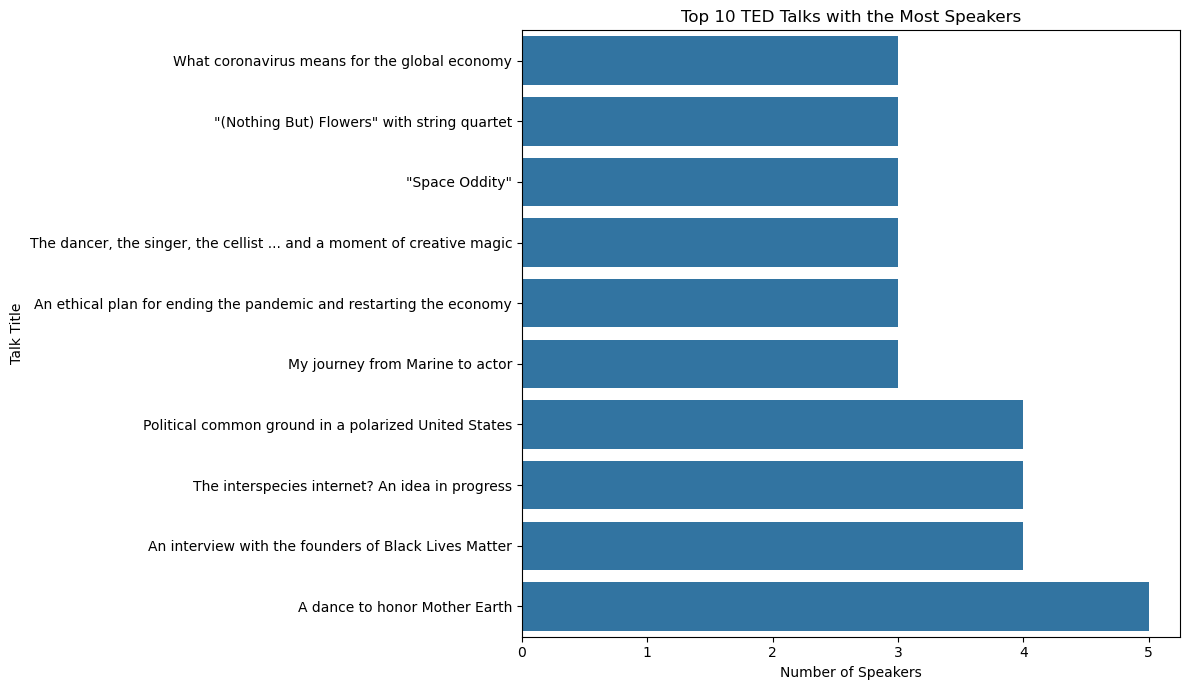

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_multi_speaker_talks.sort_values('speaker_count'),
    x='speaker_count',
    y='title'
)

plt.title('Top 10 TED Talks with the Most Speakers')
plt.xlabel('Number of Speakers')
plt.ylabel('Talk Title')
plt.tight_layout()
plt.show()

In [69]:
topic_counts = (
    df['topics']
    .dropna()
    .str.split(',')
    .explode()
    .str.strip()
)

topic_counts = topic_counts[topic_counts != ''].value_counts()

In [70]:
top_topics = topic_counts.head(15).reset_index()
top_topics.columns = ['topics', 'count']

In [71]:
display(top_topics)

,topics,count
0,teded math,8
1,animation teded math,5
2,teded math animation,3
3,teded animation education math,3
4,cities culture design transportation,2
5,ted fellows photography war,2
6,art creativity,2
7,design entertainment live music music technology,2
8,charter for compassion compassion global issue...,2
9,architecture cities design infrastructure,2


In [72]:
print("Total unique topics:", topic_counts.nunique())

Total unique topics: 5


In [73]:
print("Total unique topics:", len(topic_counts))

Total unique topics: 3976


In [74]:
topic_counts = (
    df['topics']
    .dropna()
    .str.split()
    .explode()
    .str.strip()
)

topic_counts = topic_counts[topic_counts != ''].value_counts()

print("Total unique individual topics:", len(topic_counts))

top_topics = topic_counts.head(15).reset_index()
top_topics.columns = ['topics', 'count']

display(top_topics)

Total unique individual topics: 480


,topics,count
0,science,1138
1,technology,979
2,health,943
3,change,683
4,culture,680
5,global,668
6,design,651
7,social,597
8,tedx,581
9,issues,574


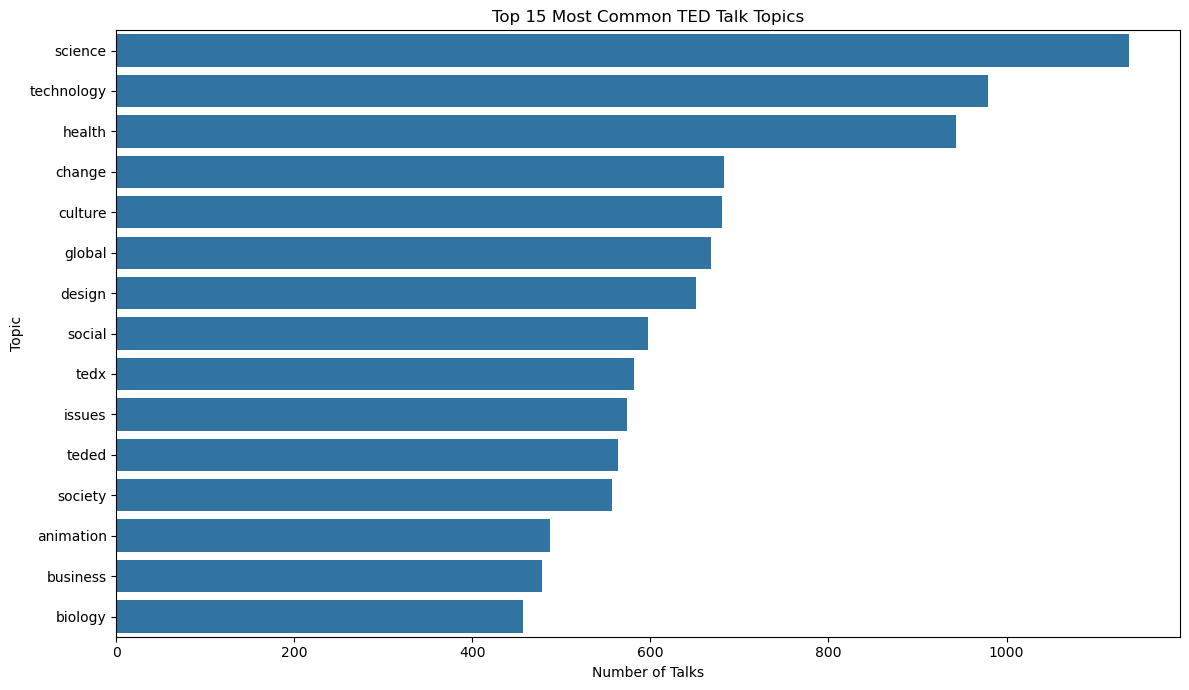

In [75]:
plt.figure(figsize=(12, 7))

sns.barplot(data=top_topics, x='count', y='topics')

plt.title('Top 15 Most Common TED Talk Topics')
plt.xlabel('Number of Talks')
plt.ylabel('Topic')
plt.tight_layout()
plt.show()

In [76]:
text_cols = ["title", "description", "transcript", "about_speakers"]

for col in text_cols:
    text = df[col].fillna("").astype(str).str.strip()
    words = text.str.split().str.len()
    print(f"\n{col}")
    print("Empty:", text.eq("").sum())
    print("Mean words:", round(words.mean(), 2))
    print("Median words:", words.median())
    print("Shortest:", words.min())
    print("Longest:", words.max())


title
Empty: 0
Mean words: 6.73
Median words: 6.0
Shortest: 1
Longest: 17

description
Empty: 0
Mean words: 57.49
Median words: 56.0
Shortest: 9
Longest: 140

transcript
Empty: 0
Mean words: 1786.58
Median words: 1747.5
Shortest: 2
Longest: 11078

about_speakers
Empty: 0
Mean words: 22.4
Median words: 21.0
Shortest: 2
Longest: 236


,Event,Talk Count
0,ted-ed,556
1,ted2018,96
2,ted2017,96
3,ted2019,91
4,ted2014,84
5,ted2009,81
6,ted2016,75
7,ted2013,75
8,ted2015,75
9,ted2011,70


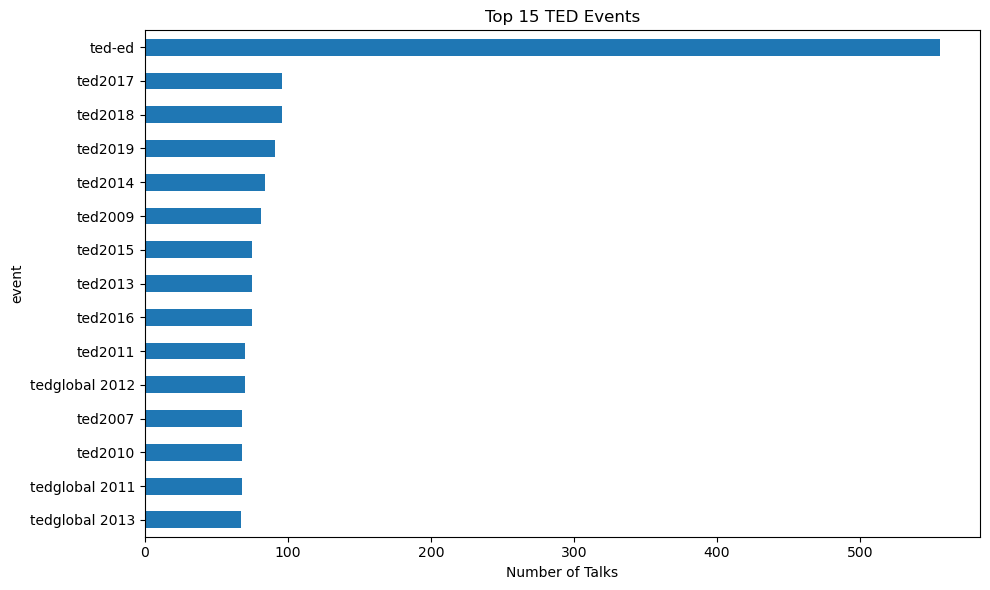

In [77]:
event_counts = df["event"].fillna("Unknown").value_counts()
display(event_counts.head(15).rename_axis("Event").reset_index(name="Talk Count"))

event_counts.head(15).sort_values().plot(kind="barh", figsize=(10, 6))
plt.title("Top 15 TED Events")
plt.xlabel("Number of Talks")
plt.tight_layout()
plt.show()

count    4004.000000
mean      150.091159
std       247.369036
min         0.000000
25%        46.000000
50%        89.000000
75%       162.000000
max      6449.000000
Name: comments, dtype: float64
Missing comments: 0


,title,speaker_1,comments
94,Militant atheism,richard dawkins,6449.0
4,Do schools kill creativity?,sir ken robinson,4931.0
617,Science can answer moral questions,sam harris,3424.0
1735,How do you explain consciousness?,david chalmers,3006.0
197,My stroke of insight,jill bolte taylor,2984.0
1296,Your body language may shape who you are,amy cuddy,2633.0
911,Taking imagination seriously,janet echelman,2529.0
799,On reading the Koran,lesley hazleton,2463.0
631,The danger of science denial,michael specter,2366.0
796,The power of vulnerability,bren brown,2209.0


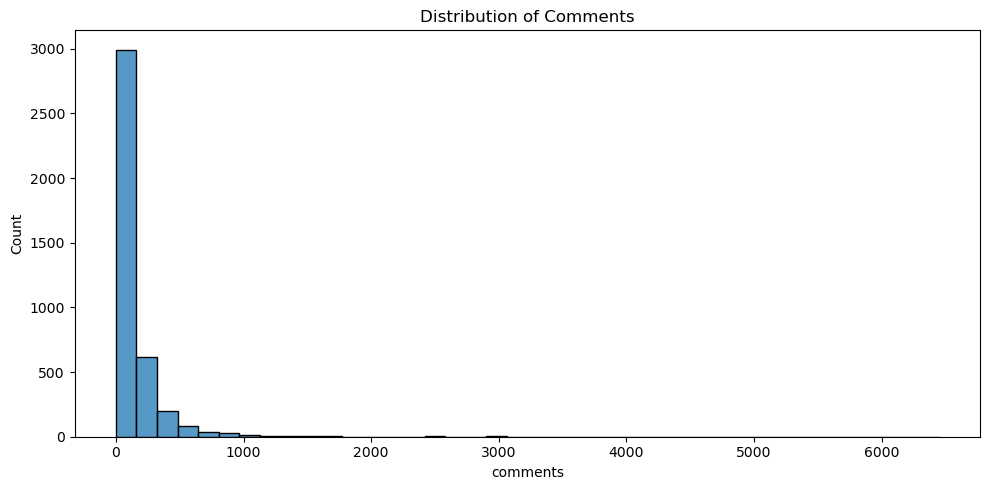

In [78]:
print(df["comments"].describe())
print("Missing comments:", df["comments"].isna().sum())

display(df.nlargest(10, "comments")[["title", "speaker_1", "comments"]])

plt.figure(figsize=(10, 5))
sns.histplot(df["comments"].dropna(), bins=40)
plt.title("Distribution of Comments")
plt.tight_layout()
plt.show()

In [79]:
related = df["related_talks"].fillna("").astype(str)

df["related_count"] = related.apply(
    lambda x: sum(bool(item.strip()) for item in x.replace("[", "").replace("]", "").split(","))
)

print(df["related_count"].describe())
print("Talks without related-talk data:", related.str.strip().eq("").sum())
display(df[["title", "related_talks", "related_count"]].head(10))

count    4004.000000
mean        6.491508
std         0.860594
min         1.000000
25%         6.000000
50%         6.000000
75%         7.000000
max        12.000000
Name: related_count, dtype: float64
Talks without related-talk data: 0


,title,related_talks,related_count
0,Averting the climate crisis,"{243: 'new thinking on the climate crisis', 54...",6
1,The best stats you've ever seen,"{2056: ""own your body's data"", 2296: 'a visual...",6
2,Simplicity sells,"{1725: '10 top time-saving tech tips', 2274: '...",6
3,Greening the ghetto,{1041: '3 stories of local eco-entrepreneurshi...,6
4,Do schools kill creativity?,"{865: 'bring on the learning revolution!', 173...",7
5,Behind the design of Seattle's library,{750: 'building a theater that remakes itself'...,8
6,Letting go of God,"{22: 'why people believe weird things', 94: ""l...",7
7,Let's teach religion -- all religion -- in sch...,"{71: 'a life of purpose', 2011: 'is religion g...",6
8,A life of purpose,"{94: ""let's teach religion -- all religion -- ...",7
9,My wish: A global day of film,{2228: 'how virtual reality can create the ult...,6


In [80]:

import os
import json
import pandas as pd

os.makedirs("ted_artifacts", exist_ok=True)

# 1. Check final dataset
quality_report = {
    "total_talks": int(len(df)),
    "total_columns_before_feature_creation": int(len(df.columns) - 1),
    "duplicate_talk_ids": int(df["talk_id"].duplicated().sum()),
    "duplicate_titles": int(df["title"].duplicated().sum()),
    "missing_values": {
        col: int(count)
        for col, count in df.isnull().sum().items()
    },
    "empty_text_fields": {
        col: int(
            df[col].fillna("").astype(str).str.strip().eq("").sum()
        )
        for col in [
            "title", "topics", "description",
            "about_speakers", "transcript"
        ]
    }
}

print(json.dumps(quality_report, indent=4))

# 2. Export cleaned dataset
df.to_csv(
    "ted_artifacts/cleaned_ted_talks.csv",
    index=False
)

# 3. Save data-quality report
with open("ted_artifacts/data_quality_report.json", "w") as f:
    json.dump(quality_report, f, indent=4)

print("\nCleaned dataset and quality report saved.")


{
    "total_talks": 4004,
    "total_columns_before_feature_creation": 20,
    "duplicate_talk_ids": 0,
    "duplicate_titles": 0,
    "missing_values": {
        "talk_id": 0,
        "title": 0,
        "speaker_1": 0,
        "all_speakers": 0,
        "occupations": 0,
        "about_speakers": 0,
        "views": 0,
        "recorded_date": 0,
        "published_date": 0,
        "event": 0,
        "native_lang": 0,
        "available_lang": 0,
        "comments": 0,
        "duration": 0,
        "topics": 0,
        "related_talks": 0,
        "url": 0,
        "description": 0,
        "transcript": 0,
        "year": 0,
        "related_count": 0
    },
    "empty_text_fields": {
        "title": 0,
        "topics": 0,
        "description": 0,
        "about_speakers": 0,
        "transcript": 0
    }
}

Cleaned dataset and quality report saved.


In [81]:
df_new = df.copy()

In [82]:
df_new.head()

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,available_lang,comments,duration,topics,related_talks,url,description,transcript,year,related_count
0,1,Averting the climate crisis,al gore,al gore,{0: ['climate advocate']},0 nobel laureate al gore focused the worlds at...,3523392,2006-02-25,2006-06-27,ted2006,...,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,alternative energy cars climate change culture...,"{243: 'new thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,with the same humor and humanity he exuded in ...,thank you so much chris and its truly a great ...,2006,6
1,92,The best stats you've ever seen,hans rosling,hans rosling,{0: ['global health expert; data visionary']},0 in hans roslings hands data sings global tre...,14501685,2006-02-22,2006-06-27,ted2006,...,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,africa asia google demo economics global issue...,"{2056: ""own your body's data"", 2296: 'a visual...",https://www.ted.com/talks/hans_rosling_the_bes...,youve never seen data presented like this with...,about 10 years ago i took on the task to teach...,2006,6
2,7,Simplicity sells,david pogue,david pogue,{0: ['technology columnist']},0 david pogue is the personal technology colum...,1920832,2006-02-24,2006-06-27,ted2006,...,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,computers entertainment interface design media...,"{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,new york times columnist david pogue takes aim...,music the sound of silence simon garfunkel he...,2006,6
3,53,Greening the ghetto,majora carter,majora carter,{0: ['activist for environmental justice']},0 majora carter redefined the field of environ...,2664069,2006-02-26,2006-06-27,ted2006,...,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,macarthur grant activism business cities envir...,{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,in an emotionally charged talk macarthurwinnin...,if youre here today and im very happy that yo...,2006,6
4,66,Do schools kill creativity?,sir ken robinson,sir ken robinson,"{0: ['author', 'educator']}",0 creativity expert sir ken robinson challenge...,65051954,2006-02-25,2006-06-27,ted2006,...,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,children creativity culture dance education pa...,"{865: 'bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,sir ken robinson makes an entertaining and pro...,good morning how are you audience good its bee...,2006,7


In [83]:
df_new.columns.to_list()

['talk_id',
 'title',
 'speaker_1',
 'all_speakers',
 'occupations',
 'about_speakers',
 'views',
 'recorded_date',
 'published_date',
 'event',
 'native_lang',
 'available_lang',
 'comments',
 'duration',
 'topics',
 'related_talks',
 'url',
 'description',
 'transcript',
 'year',
 'related_count']

In [84]:
df_new.isnull().sum()

talk_id           0
title             0
speaker_1         0
all_speakers      0
occupations       0
about_speakers    0
views             0
recorded_date     0
published_date    0
event             0
native_lang       0
available_lang    0
comments          0
duration          0
topics            0
related_talks     0
url               0
description       0
transcript        0
year              0
related_count     0
dtype: int64

In [85]:
df_new["year"] = pd.to_datetime(
    df_new["published_date"],
    errors="coerce"
).dt.year

In [86]:
df_new.columns.to_list()

['talk_id',
 'title',
 'speaker_1',
 'all_speakers',
 'occupations',
 'about_speakers',
 'views',
 'recorded_date',
 'published_date',
 'event',
 'native_lang',
 'available_lang',
 'comments',
 'duration',
 'topics',
 'related_talks',
 'url',
 'description',
 'transcript',
 'year',
 'related_count']

In [87]:
df.isnull().sum()

talk_id           0
title             0
speaker_1         0
all_speakers      0
occupations       0
about_speakers    0
views             0
recorded_date     0
published_date    0
event             0
native_lang       0
available_lang    0
comments          0
duration          0
topics            0
related_talks     0
url               0
description       0
transcript        0
year              0
related_count     0
dtype: int64

In [88]:
print("df nulls:", df["all_speakers"].isnull().sum())
print("df_new nulls:", df_new["all_speakers"].isnull().sum())

print("df shape:", df.shape)
print("df_new shape:", df_new.shape)

print("df null rows:")
print(df[df["all_speakers"].isnull()]["talk_id"])

print("df_new null rows:")
print(df_new[df_new["all_speakers"].isnull()]["talk_id"])

df nulls: 0
df_new nulls: 0
df shape: (4004, 21)
df_new shape: (4004, 21)
df null rows:
Series([], Name: talk_id, dtype: int64)
df_new null rows:
Series([], Name: talk_id, dtype: int64)


In [89]:
df_new["all_speakers"] = df_new["all_speakers"].fillna(
    df_new["speaker_1"]
)

In [90]:
df[['related_talks','related_count']].head()

,related_talks,related_count
0,"{243: 'new thinking on the climate crisis', 54...",6
1,"{2056: ""own your body's data"", 2296: 'a visual...",6
2,"{1725: '10 top time-saving tech tips', 2274: '...",6
3,{1041: '3 stories of local eco-entrepreneurshi...,6
4,"{865: 'bring on the learning revolution!', 173...",7


In [91]:
drop_columns = [
    "all_speakers",
    "occupations",
    "published_date",
    "recorded_date",
    "event",
    "native_lang",
    "available_lang",
    "comments"
]

df_new.drop(columns=drop_columns, inplace=True)

print(df_new.shape)
print(df_new.columns.tolist())

(4004, 13)
['talk_id', 'title', 'speaker_1', 'about_speakers', 'views', 'duration', 'topics', 'related_talks', 'url', 'description', 'transcript', 'year', 'related_count']


In [92]:
print("Duplicate talk IDs:", df_new["talk_id"].duplicated().sum())
print("Duplicate titles:", df_new["title"].duplicated().sum())

Duplicate talk IDs: 0
Duplicate titles: 0


In [110]:
text_columns = [
    "title",
    "topics",
    "description",
    "about_speakers",
    "transcript"
]

for col in text_columns:
    print(col, "empty values:", df_new[col].fillna("").astype(str).str.strip().eq("").sum())

title empty values: 0
topics empty values: 0
description empty values: 0
about_speakers empty values: 0
transcript empty values: 0


In [111]:
df_new["combined_text"] = (
    (df_new["title"].fillna("") + " ") * 5
    + (df_new["topics"].fillna("") + " ") * 5
    + (df_new["description"].fillna("") + " ") * 3
    + df_new["transcript"].fillna("")
)

df_new[["title", "combined_text"]].head()


,title,combined_text
0,Averting the climate crisis,Averting the climate crisis Averting the clima...
1,The best stats you've ever seen,The best stats you've ever seen The best stats...
2,Simplicity sells,Simplicity sells Simplicity sells Simplicity s...
3,Greening the ghetto,Greening the ghetto Greening the ghetto Greeni...
4,Do schools kill creativity?,Do schools kill creativity? Do schools kill cr...


In [112]:
df_new["combined_text"].iloc[0]

'Averting the climate crisis Averting the climate crisis Averting the climate crisis Averting the climate crisis Averting the climate crisis alternative energy cars climate change culture environment global issues science sustainability technology alternative energy cars climate change culture environment global issues science sustainability technology alternative energy cars climate change culture environment global issues science sustainability technology alternative energy cars climate change culture environment global issues science sustainability technology alternative energy cars climate change culture environment global issues science sustainability technology with the same humor and humanity he exuded in an inconvenient truth al gore spells out 15 ways that individuals can address climate change immediately from buying a hybrid to inventing a new hotter brand name for global warming with the same humor and humanity he exuded in an inconvenient truth al gore spells out 15 ways t

In [101]:
df_new.columns

Index(['talk_id', 'title', 'speaker_1', 'about_speakers', 'views', 'duration',
       'topics', 'related_talks', 'url', 'description', 'transcript', 'year',
       'related_count', 'combined_text_v2'],
      dtype='object')

In [102]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    df_new["combined_text_v2"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))
print("Number of talks:", len(df_new))

TF-IDF matrix shape: (4004, 30000)
Vocabulary size: 30000
Number of talks: 4004


In [103]:
def recommend_talks(talk_title, top_n=5):
    matches = df_new.index[
        df_new["title"].str.casefold() == talk_title.casefold()
    ].tolist()

    if not matches:
        print("Talk title not found.")
        return

    idx = matches[0]

    scores = similarity_matrix[idx].copy()
    scores[idx] = -1 

    top_indices = np.argsort(scores)[::-1][:top_n]

    result = df_new.iloc[top_indices][
        ["talk_id", "title", "speaker_1", "year", "url"]
    ].copy()

    result["similarity_score"] = scores[top_indices]

    return result.reset_index(drop=True)

In [104]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(tfidf_matrix)

print("Similarity matrix shape:", similarity_matrix.shape)

Similarity matrix shape: (4004, 4004)


In [105]:
recommend_talks("Averting the climate crisis", top_n=5)

,talk_id,title,speaker_1,year,url,similarity_score
0,535,What comes after An Inconvenient Truth?,al gore,2009,https://www.ted.com/talks/al_gore_what_comes_a...,0.201662
1,243,New thinking on the climate crisis,al gore,2008,https://www.ted.com/talks/al_gore_new_thinking...,0.200835
2,2441,The case for optimism on climate change,al gore,2016,https://www.ted.com/talks/al_gore_the_case_for...,0.177279
3,54715,How we can turn the tide on climate,chris anderson,2019,https://www.ted.com/talks/christiana_figueres_...,0.167950
4,128,Salvation (and profit) in greentech,john doerr,2007,https://www.ted.com/talks/john_doerr_salvation...,0.165743


In [106]:
df_new.loc[
    df_new["title"] == "Averting the climate crisis",
    ["talk_id", "related_talks", "related_count"]
]

,talk_id,related_talks,related_count
0,1,"{243: 'new thinking on the climate crisis', 54...",6


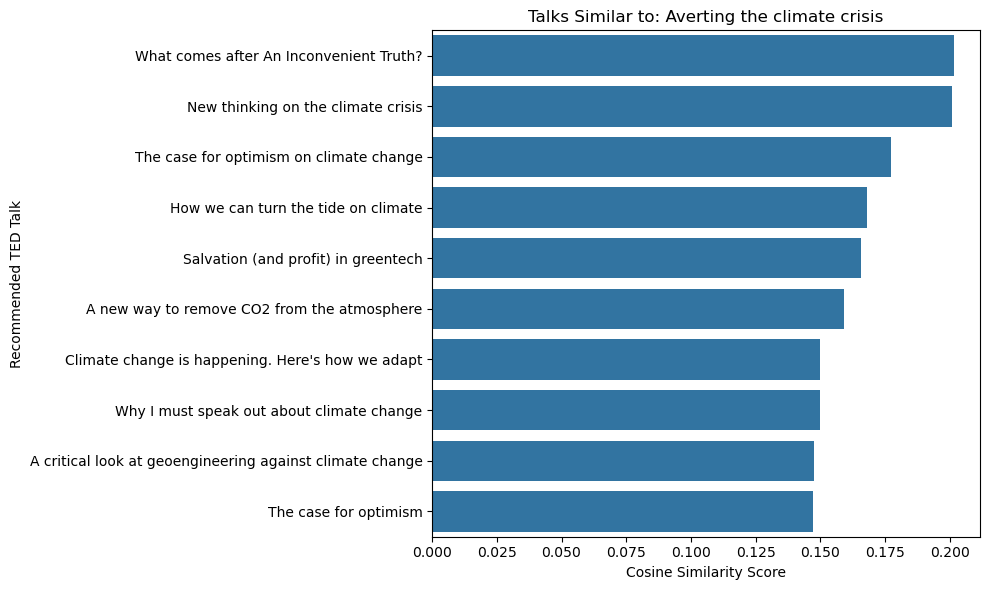

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns

talk_title = "Averting the climate crisis"

recommendations = recommend_talks(talk_title, top_n=10)

if recommendations is not None:
    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=recommendations,
        x="similarity_score",
        y="title"
    )

    plt.title(f"Talks Similar to: {talk_title}")
    plt.xlabel("Cosine Similarity Score")
    plt.ylabel("Recommended TED Talk")
    plt.tight_layout()
    plt.show()

,Feature,TF-IDF Score
0,climate crisis,0.121888
1,culture environment,0.121119
2,technology alternative,0.118852
3,science sustainability,0.115291
4,issues science,0.114096
5,sustainability technology,0.109113
6,nashville,0.107873
7,cars trucks,0.107873
8,environment global,0.104568
9,humor humanity,0.104524


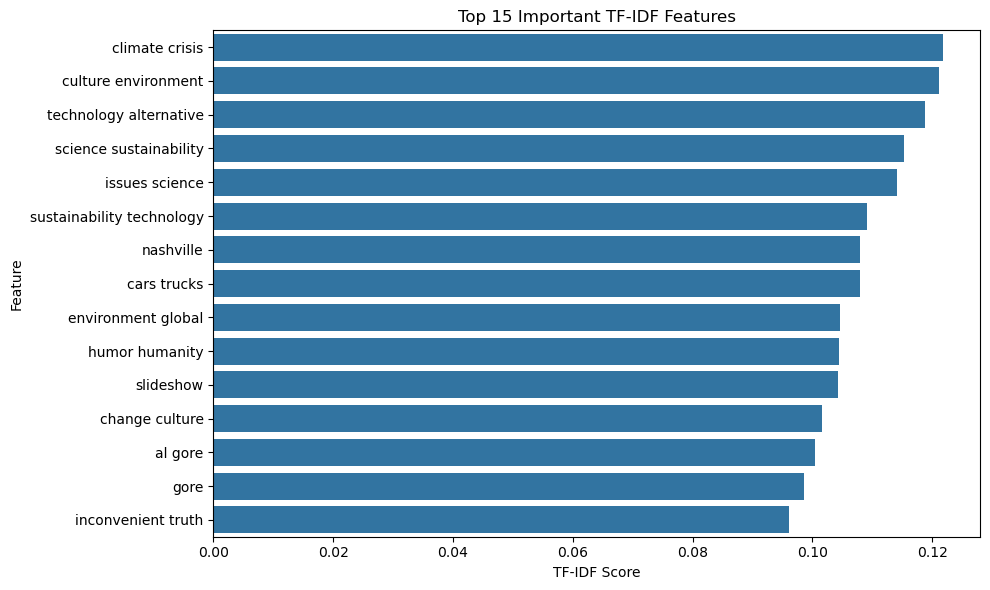

In [108]:
# Extract TF-IDF feature names
feature_names = tfidf_vectorizer.get_feature_names_out()

# Select a TED Talk
talk_idx = df_new.index[
    df_new['title'] == "Averting the climate crisis"
][0]

# Get TF-IDF scores
talk_features = tfidf_matrix[talk_idx].toarray().flatten()

# Select top 15 features
top_indices = np.argsort(talk_features)[::-1][:15]

feature_df = pd.DataFrame({
    'Feature': feature_names[top_indices],
    'TF-IDF Score': talk_features[top_indices]
})

display(feature_df)

# Visualize
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_df,
    x='TF-IDF Score',
    y='Feature'
)

plt.title('Top 15 Important TF-IDF Features')
plt.tight_layout()
plt.show()

In [109]:
import joblib
import os

os.makedirs("ted_artifacts", exist_ok=True)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf_vectorizer,
    "ted_artifacts/tfidf_vectorizer.pkl"
)

# Save vectorized representations
joblib.dump(
    tfidf_matrix,
    "ted_artifacts/tfidf_matrix.pkl"
)

# Save cosine similarity matrix
joblib.dump(
    similarity_matrix,
    "ted_artifacts/similarity_matrix.pkl"
)

print("All TF-IDF artifacts saved successfully!")

All TF-IDF artifacts saved successfully!
